# Member C — Bipartite Deviation Network

Who stands out from the class consensus, and on which issues?

In [1]:
import sys, pathlib

# This member's own modules. `common` needs no path work -- it is an
# installed package (pip install -e .), so it imports from any directory.
sys.path.insert(0, str(pathlib.Path.cwd() / "src"))

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from community import best_partition
from scipy.stats import pearsonr, spearmanr

from load import load_clean, zscore_items, item_block, item_block_name, SEED
from build import (build_bipartite, sensitivity_sweep, student_projection,
                        item_projection, export_gexf, PRIMARY_CUTOFF,
                        SENSITIVITY_CUTOFFS, bipartite_summary)
from bipartite_metrics import (degree_table, compute_nodf, nodf_null,
                                    core_periphery_students,
                                    core_periphery_items, bipartite_clustering,
                                    louvain_communities, modularity_null)
from randomwalk import compute_mfpt, robustness_experiment, relative_mfpt
from common import viz

viz.apply_style()

FIGURES_DIR = pathlib.Path("figures")
TABLES_DIR = pathlib.Path("tables")
GEXF_DIR = pathlib.Path("gexf")
for d in [FIGURES_DIR, TABLES_DIR, GEXF_DIR]:
    d.mkdir(parents=True, exist_ok=True)

BLOCK_COLORS = viz.BLOCK_COLORS   # shared across all three members' figures
BLOCK_NAMES = viz.BLOCK_NAMES     # defined only in common/viz.py, so labels cannot drift
# No rcParams override here: viz.apply_style() governs every figure in the
# repo, so A's, B's and C's plots read as one document.
print("Imports OK")


Imports OK


## 1. Load & clean data

In [2]:
clean = load_clean()
z = zscore_items(clean)
print(f"Respondents: {clean.shape[0]}, Items: {clean.shape[1]}")
print(f"NaN in z-scores: {z.isna().sum().sum()}")


Respondents: 87, Items: 60
NaN in z-scores: 62


## 2. Build bipartite graph & sensitivity sweep

In [3]:
G = build_bipartite(z, cutoff=PRIMARY_CUTOFF)
summary = bipartite_summary(G)
print("Primary bipartite graph (cutoff=1.0):")
for k, v in summary.items():
    print(f"  {k}: {v}")

sweep = sensitivity_sweep(z)
sweep.to_csv(TABLES_DIR / "table01_sensitivity_sweep.csv", index=False)
print("\nSensitivity sweep:")
print(sweep.to_string(index=False))


Primary bipartite graph (cutoff=1.0):
  n_students: 87
  n_items: 60
  n_edges: 1200
  density: 0.22988505747126436
  student_deg_mean: 13.793103448275861
  student_deg_max: 35
  item_deg_mean: 20.0
  item_deg_max: 60
  isolated_students: 0
  isolated_items: 0

Sensitivity sweep:
 cutoff  n_edges  density  student_deg_mean  item_deg_mean  isolated_students  isolated_items
   0.75     2856 0.547126         32.827586      47.600000                  0               0
   1.00     1200 0.229885         13.793103      20.000000                  0               0
   1.50      442 0.084674          5.080460       7.366667                  4               0


## 3. Degree distributions

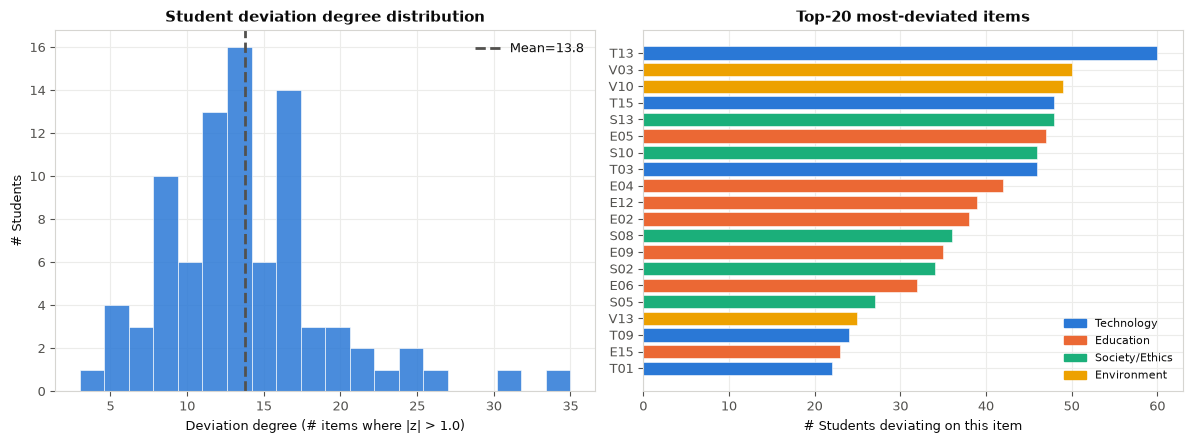

Saved fig01_degree_distributions.png


In [4]:
std_deg = degree_table(G, "student")
itm_deg = degree_table(G, "item")
std_deg.to_csv(TABLES_DIR / "table02_student_degree.csv", index=False)
itm_deg.to_csv(TABLES_DIR / "table03_item_degree.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Student degree histogram
ax = axes[0]
ax.hist(std_deg["degree"], bins=20, color=viz.CAT[0], edgecolor="white", linewidth=0.5, alpha=0.85)
ax.axvline(std_deg["degree"].mean(), color=viz.INK_SOFT, lw=2, linestyle="--", label=f'Mean={std_deg["degree"].mean():.1f}')
ax.set_xlabel("Deviation degree (# items where |z| > 1.0)")
ax.set_ylabel("# Students")
ax.set_title("Student deviation degree distribution")
ax.legend(framealpha=0)

# Item degree bar (top 20, coloured by block)
ax = axes[1]
top20 = itm_deg.head(20).copy()
colors = [BLOCK_COLORS[b] for b in top20["block"]]
bars = ax.barh(range(len(top20)), top20["degree"], color=colors, edgecolor="white", linewidth=0.4)
ax.set_yticks(range(len(top20)))
ax.set_yticklabels(top20["node"], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("# Students deviating on this item")
ax.set_title("Top-20 most-deviated items")
# Legend colours come from the same dict as the bars, so the two cannot
# disagree -- they previously did.
legend_patches = [mpatches.Patch(color=BLOCK_COLORS[k], label=BLOCK_NAMES[k])
                  for k in "TESV"]
ax.legend(handles=legend_patches, fontsize=8, framealpha=0)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig01_degree_distributions.png", bbox_inches="tight")
plt.show()
print("Saved fig01_degree_distributions.png")


## 4. Bipartite network layout

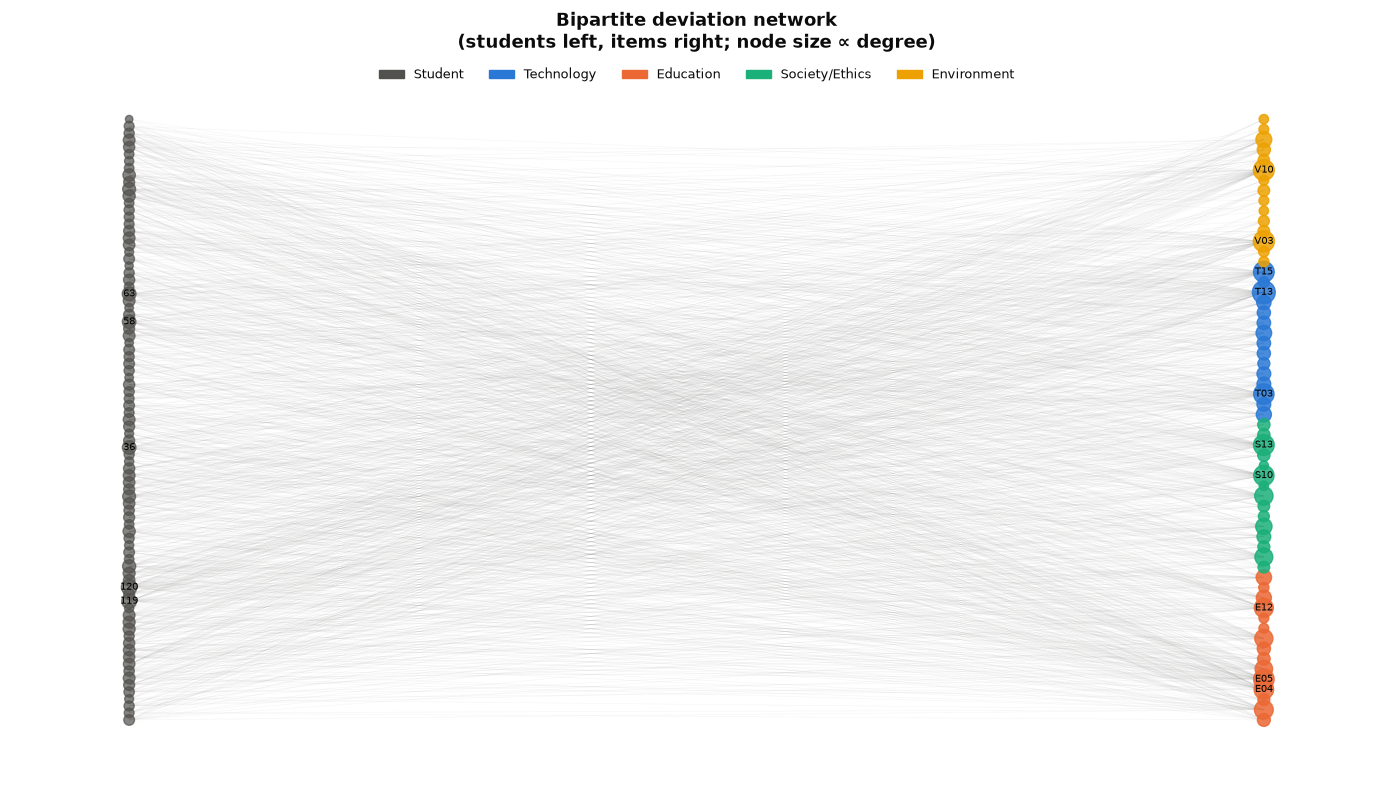

Saved fig02_bipartite_layout.png


In [5]:
fig, ax = plt.subplots(figsize=(14, 8))

students = [n for n, d in G.nodes(data=True) if d.get("node_type") == "student"]
items = [n for n, d in G.nodes(data=True) if d.get("node_type") == "item"]

# Layout: students on left, items on right
pos = {}
for i, s in enumerate(sorted(students)):
    pos[s] = (0, i / max(len(students) - 1, 1))
for j, q in enumerate(sorted(items)):
    pos[q] = (1, j / max(len(items) - 1, 1))

# Node sizes proportional to degree
std_deg_dict = {r["node"]: r["degree"] for _, r in std_deg.iterrows()}
itm_deg_dict = {r["node"]: r["degree"] for _, r in itm_deg.iterrows()}

s_sizes = [20 + std_deg_dict.get(s, 0) * 3 for s in students]
q_sizes = [30 + itm_deg_dict.get(q, 0) * 4 for q in items]
q_colors = [BLOCK_COLORS[item_block(q)] for q in items]

# Draw edges (thin, semi-transparent)
edge_weights = [G[u][v]["weight"] for u, v in G.edges()]
max_w = max(edge_weights) if edge_weights else 1
# Edges are data, so they take a data ink (INK_SOFT), not the axis grey --
# at 1200 edges an axis-coloured bundle disappears against the background.
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.06, width=0.4,
                        edge_color=viz.INK_SOFT)

# Draw nodes
# Students are not a block, so they get a neutral rather than a block colour:
# drawing them in T-blue made "Student" and "Technology" the same colour.
nx.draw_networkx_nodes(G, pos, nodelist=students, ax=ax,
                        node_color=viz.INK_SOFT, node_size=s_sizes, alpha=0.7)
nx.draw_networkx_nodes(G, pos, nodelist=items, ax=ax,
                        node_color=q_colors, node_size=q_sizes, alpha=0.85)

# Label top items only
top_items_to_label = set(itm_deg.head(10)["node"])
top_students_to_label = set(std_deg.head(5)["node"])
label_pos = {n: p for n, p in pos.items()
             if n in top_items_to_label or n in top_students_to_label}
labels = {n: str(n) for n in label_pos}
nx.draw_networkx_labels(G, label_pos, labels=labels, ax=ax, font_size=7)

legend_patches = [mpatches.Patch(color=viz.INK_SOFT, label="Student")]
legend_patches += [mpatches.Patch(color=BLOCK_COLORS[k], label=BLOCK_NAMES[k])
                   for k in "TESV"]
ax.legend(handles=legend_patches, loc="upper center", ncol=5, framealpha=0, fontsize=9)
ax.set_title("Bipartite deviation network\n(students left, items right; node size ∝ degree)", fontsize=13)
ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig02_bipartite_layout.png", bbox_inches="tight")
plt.show()
print("Saved fig02_bipartite_layout.png")


## 5. NODF nestedness & core-periphery

NODF nestedness: 41.79 (rows=44.48, cols=39.10)


  vs degree-preserving null: 41.00 +/- 0.26  (z = +3.08, excess = +0.79 points)
Core students (top 20%): 17
Core items (top 20%): 12


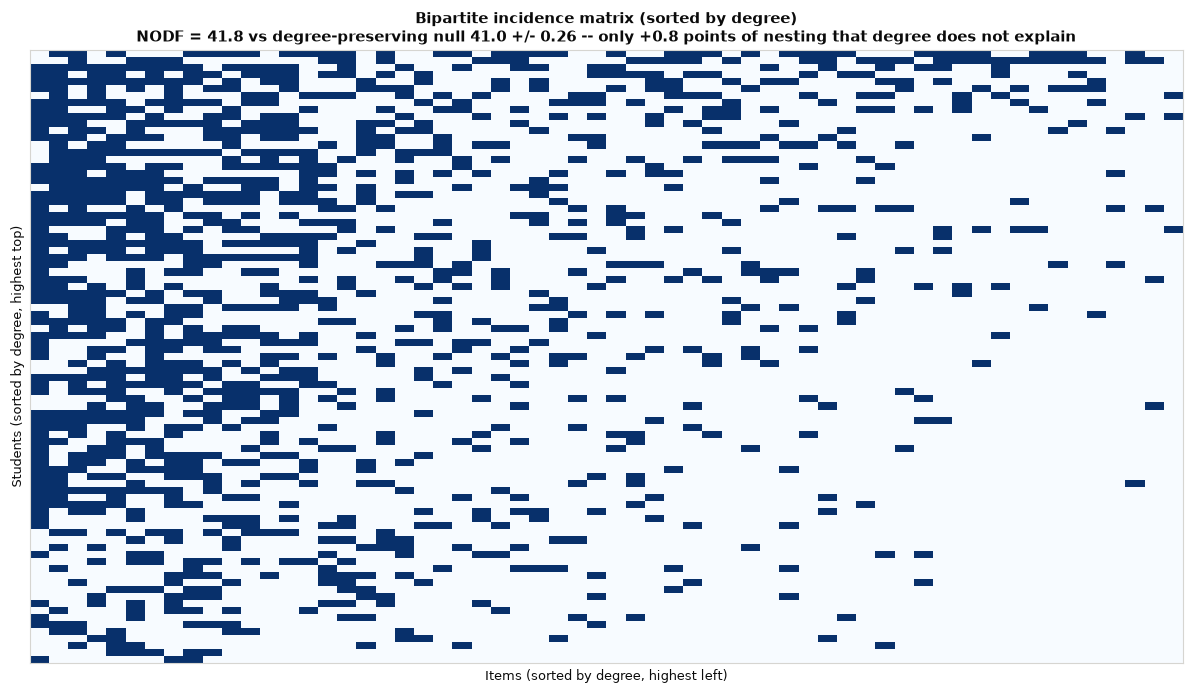

Saved fig03_nestedness_matrix.png


In [6]:
nodf = compute_nodf(G)
print(f"NODF nestedness: {nodf['nodf']:.2f} (rows={nodf['nodf_rows']:.2f}, cols={nodf['nodf_cols']:.2f})")

# NODF rises mechanically with heterogeneous degrees, and degrees here are very
# heterogeneous by construction (3 to 35 deviations per student). Without a null
# that fixes both degree sequences, a bare NODF cannot separate "dissent is
# organised as a hierarchy" from "some students just deviate more than others".
nodf_vs_null = nodf_null(G, n_rep=30)
print(f"  vs degree-preserving null: {nodf_vs_null['nodf_null_mean']:.2f} "
      f"+/- {nodf_vs_null['nodf_null_sd']:.2f}  "
      f"(z = {nodf_vs_null['z']:+.2f}, excess = {nodf_vs_null['excess']:+.2f} points)")

pd.DataFrame([{**nodf, **nodf_vs_null}]).to_csv(TABLES_DIR / "table04_nodf.csv", index=False)

cp_s = core_periphery_students(G, top_frac=0.20)
cp_i = core_periphery_items(G, top_frac=0.20)
n_core_s = sum(1 for v in cp_s.values() if v == "core")
n_core_i = sum(1 for v in cp_i.values() if v == "core")
print(f"Core students (top 20%): {n_core_s}")
print(f"Core items (top 20%): {n_core_i}")

# Sorted incidence matrix for nestedness visualisation
students_sorted = std_deg["node"].tolist()
items_sorted = itm_deg["node"].tolist()
s_idx = {s: i for i, s in enumerate(students_sorted)}
q_idx = {q: j for j, q in enumerate(items_sorted)}
M = np.zeros((len(students_sorted), len(items_sorted)), dtype=int)
for u, v in G.edges():
    if u in s_idx and v in q_idx:
        M[s_idx[u], q_idx[v]] = 1
    elif v in s_idx and u in q_idx:
        M[s_idx[v], q_idx[u]] = 1

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(M, aspect="auto", cmap="Blues", interpolation="nearest")
ax.set_xlabel("Items (sorted by degree, highest left)")
ax.set_ylabel("Students (sorted by degree, highest top)")
ax.set_title("Bipartite incidence matrix (sorted by degree)\n"
             f"NODF = {nodf['nodf']:.1f} vs degree-preserving null "
             f"{nodf_vs_null['nodf_null_mean']:.1f} +/- {nodf_vs_null['nodf_null_sd']:.2f} "
             f"-- only {nodf_vs_null['excess']:+.1f} points of nesting that degree does not explain")
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig03_nestedness_matrix.png", bbox_inches="tight")
plt.show()
print("Saved fig03_nestedness_matrix.png")


## 6. One-mode projections & communities

In [7]:
Ps = student_projection(G)
Pi = item_projection(G)
part_s, Q_s = louvain_communities(Ps)
part_i, Q_i = louvain_communities(Pi)
n_comm_s = len(set(part_s.values()))
n_comm_i = len(set(part_i.values()))
print(f"Student co-dissent projection: {Ps.number_of_edges()} edges, {n_comm_s} communities, Q={Q_s:.3f}")
print(f"Item co-deviation projection: {Pi.number_of_edges()} edges, {n_comm_i} communities, Q={Q_i:.3f}")

# Louvain always returns *a* partition, so a small Q is only meaningful next to
# what a structureless graph with the same degrees would score.
null_rows = []
for nm, P in [("student_codissent", Ps), ("item_codeviation", Pi)]:
    mn = modularity_null(P)
    mn["projection"] = nm
    null_rows.append(mn)
    print(f"  {nm}: Q={mn['modularity_observed']:.4f} vs configuration-model null "
          f"{mn['modularity_null_mean']:.4f} +/- {mn['modularity_null_sd']:.4f}  "
          f"(z = {mn['z_score']:+.2f})")
pd.DataFrame(null_rows).to_csv(TABLES_DIR / "table05_modularity_null.csv", index=False)

comm_df_s = pd.DataFrame([{"node": k, "community": v} for k, v in part_s.items()])
comm_df_i = pd.DataFrame([{"node": k, "community": v, "block": item_block(k)} for k, v in part_i.items()])
comm_df_s.to_csv(TABLES_DIR / "table06_student_communities.csv", index=False)
comm_df_i.to_csv(TABLES_DIR / "table07_item_communities.csv", index=False)

# Item community composition
print("\nItem communities by block:")
print(comm_df_i.groupby(["community", "block"]).size().unstack(fill_value=0))


Student co-dissent projection: 3699 edges, 2 communities, Q=0.037
Item co-deviation projection: 1684 edges, 2 communities, Q=0.076


  student_codissent: Q=0.0368 vs configuration-model null 0.0567 +/- 0.0032  (z = -6.14)


  item_codeviation: Q=0.0761 vs configuration-model null 0.0671 +/- 0.0041  (z = +2.21)

Item communities by block:
block      E   S  T   V
community              
0          8  11  8  13
1          7   4  7   2


## 7. Dynamical process: random walk and mean first-passage time

A walker hops student -> item -> student -> ..., so it can only move between
two students through an issue they both deviate on. The mean first-passage
time MFPT(s -> t) is therefore an *issue-mediated distance*: how long it takes
dissent to travel from one student to another through shared contrarian
positions.

We compute it exactly from the fundamental matrix
`Z = (I - T + 1 pi^T)^-1`, `H_ij = (Z_jj - Z_ij) / pi_j`, using the true
stationary distribution `pi_j ∝ strength_j`. (An earlier version of this
notebook used a uniform `pi`, which is only valid on a regular graph; here
strengths span ~30x, and the uniform approximation flattened the whole MFPT
range from 25x down to 1.2x.)

Because raw MFPT to a node scales roughly as `vol / strength_j`, we also
report the **relative MFPT** `R_ij = H_ij * strength_j / vol`, which is ~1
when a student is exactly as hard to reach as their deviation count predicts.
R is what isolates genuine structure from the trivial degree effect.

In [8]:
H = compute_mfpt(G)
H.to_csv(TABLES_DIR / "table08_mfpt_matrix.csv")
R = relative_mfpt(H, G)

off = ~np.eye(H.shape[0], dtype=bool)
vals = H.values[off]
print(f"MFPT over {off.sum()} ordered student pairs "
      f"({np.isfinite(vals).mean():.1%} finite, i.e. the graph is connected):")
print(f"  mean {vals.mean():.1f} | median {np.median(vals):.1f} | "
      f"min {vals.min():.1f} | max {vals.max():.1f}  ->  {vals.max() / vals.min():.0f}x spread")

incoming = H.mean(axis=0)          # how hard student j is to REACH
rel_in = R.mean(axis=0)
dev_deg = pd.Series({s: G.degree(s) for s in H.columns})

rho = spearmanr(incoming, dev_deg).statistic
print(f"\nSpearman rho(mean incoming MFPT, deviation degree) = {rho:+.3f}")
print(f"Relative MFPT spans only {rel_in.min():.3f}-{rel_in.max():.3f} "
      f"({rel_in.max() / rel_in.min():.2f}x) once strength is divided out.")

reach = pd.DataFrame({"mean_mfpt_to": incoming, "relative_mfpt_to": rel_in,
                      "deviation_degree": dev_deg}).sort_values("mean_mfpt_to")
reach.index.name = "student"
reach.to_csv(TABLES_DIR / "table09_student_reachability.csv")
print("\nEasiest to reach:"); print(reach.head(4).round(2).to_string())
print("\nHardest to reach:"); print(reach.tail(4).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

ax = axes[0]
ax.scatter(dev_deg, incoming, s=34, color=viz.CAT[0], alpha=0.8, edgecolor="white", lw=0.6)
for sid in reach.index[-2:].tolist() + reach.index[:2].tolist():
    ax.annotate(sid, (dev_deg[sid], incoming[sid]), xytext=(5, 4),
                textcoords="offset points", fontsize=8.5, color=viz.INK)
ax.set_yscale("log")
ax.set_xlabel("Deviation degree (# items with |z| > 1)")
ax.set_ylabel("Mean MFPT to this student (steps, log)")
ax.set_title(f"Raw MFPT spans {vals.max() / vals.min():.0f}x — and it is all degree"
             f"\n(Spearman rho = {rho:+.2f})", fontsize=10.5)

ax = axes[1]
ax.scatter(dev_deg, rel_in, s=34, color=viz.CAT[1], alpha=0.8, edgecolor="white", lw=0.6)
ax.axhline(1.0, color=viz.INK_SOFT, lw=1, ls="--")
ax.text(dev_deg.max(), 1.0, " degree-only\n expectation", va="center",
        fontsize=8.5, color=viz.INK_SOFT)
ax.set_ylim(0.99, 1.13)
ax.set_xlabel("Deviation degree (# items with |z| > 1)")
ax.set_ylabel("Relative MFPT  (H · strength / vol)")
ax.set_title("Divide strength out and only 11% spread is left\n"
             "— no structural pockets of dissent", fontsize=10.5)

fig.suptitle("Issue-mediated distance is explained entirely by how much a student deviates",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig04_mfpt_structure.png")
plt.close(fig)

MFPT over 7482 ordered student pairs (100.0% finite, i.e. the graph is connected):
  mean 240.6 | median 210.7 | min 39.8 | max 1063.5  ->  27x spread

Spearman rho(mean incoming MFPT, deviation degree) = -0.971
Relative MFPT spans only 1.005-1.118 (1.11x) once strength is divided out.

Easiest to reach:
         mean_mfpt_to  relative_mfpt_to  deviation_degree
student                                                  
120             41.91              1.11                35
119             62.62              1.11                31
125             78.16              1.12                23
36              82.74              1.07                25

Hardest to reach:
         mean_mfpt_to  relative_mfpt_to  deviation_degree
student                                                  
49             462.77              1.04                 6
55             468.69              1.03                 6
67             691.16              1.01                 5
99            1048.46              1.

## 8. Robustness: do the hub issues hold the network together?

Remove the highest-deviation statements one at a time and watch what happens
to first-passage times. If E03-style items were the bridges between pockets
of dissent, deleting them should tear the network apart.

Raw mean MFPT is not a fair measure here — it scales with total edge weight,
so deleting edges moves it for purely mechanical reasons. We therefore track
the relative MFPT alongside it.

In [9]:
rob = robustness_experiment(G, n_top_items=8)
rob.to_csv(TABLES_DIR / "table10_robustness_mfpt.csv", index=False)
print(rob.to_string(index=False))

labels = rob["removed_item"].tolist()
x = np.arange(len(labels))
base_raw, base_rel = rob["mean_mfpt"].iloc[0], rob["mean_relative_mfpt"].iloc[0]

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(x, 100 * (rob["mean_mfpt"] / base_raw - 1), "o-", color=viz.CAT[0],
        lw=2, ms=7, label="raw mean MFPT")
ax.plot(x, 100 * (rob["mean_relative_mfpt"] / base_rel - 1), "s-", color=viz.CAT[1],
        lw=2, ms=7, label="relative MFPT (strength divided out)")
ax.axhline(0, color=viz.INK_SOFT, lw=1)
ax.set_xticks(x)
ax.set_xticklabels(["none"] + [f"+{l}" for l in labels[1:]], rotation=30, ha="right")
ax.set_xlabel("Highest-deviation statements removed, cumulatively")
ax.set_ylabel("Change from the intact network (%)")
ax.annotate(f"+{100 * (rob['mean_mfpt'].iloc[-1] / base_raw - 1):.1f}%",
            (x[-1], 100 * (rob["mean_mfpt"].iloc[-1] / base_raw - 1)),
            xytext=(-6, 8), textcoords="offset points", fontsize=9, color=viz.INK)
ax.annotate(f"+{100 * (rob['mean_relative_mfpt'].iloc[-1] / base_rel - 1):.1f}%",
            (x[-1], 100 * (rob["mean_relative_mfpt"].iloc[-1] / base_rel - 1)),
            xytext=(-6, -14), textcoords="offset points", fontsize=9, color=viz.INK)
ax.set_title("Deleting the eight biggest flashpoints barely dents the structure")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig05_mfpt_robustness.png")
plt.close(fig)

print(f"\nStudent pairs still connected after removing all 8: "
      f"{rob['frac_connected'].iloc[-1]:.1%}")

removed_item  n_edges  mean_mfpt  mean_relative_mfpt    max_mfpt  frac_connected
        none     1200 240.616939            1.048285 1063.484579             1.0
         T13     1140 247.498352            1.050114 1475.762557             1.0
         V03     1090 248.906760            1.051576 1425.150212             1.0
         V10     1041 251.468110            1.053244 1375.191390             1.0
         T15      993 253.734677            1.054940 1325.800050             1.0
         S13      945 259.124552            1.056720 1277.380207             1.0
         E05      898 265.676630            1.058798 1229.964776             1.0
         S10      852 271.957389            1.060870 1241.912815             1.0
         T03      806 291.162484            1.063329 2296.058012             1.0



Student pairs still connected after removing all 8: 100.0%


## 9. Cross-check: is deviation distance the same thing as disagreement?

Member A builds a *student agreement* network from the cosine similarity of the
same z-scored vectors. If "students who deviate on the same issues" were just a
restatement of "students who think alike", the two should track each other.

We recompute A's similarity here from our own `load.py` (no cross-imports
between member directories) and correlate it against the symmetrised MFPT.

In [10]:
zz = z.to_numpy()
valid, filled = ~np.isnan(zz), np.nan_to_num(zz)
ids = list(z.index)
n = len(ids)

# member A's edge rule: pairwise-complete cosine on z-scores, >= 20 shared items
S = np.full((n, n), np.nan)
for i in range(n):
    for j in range(i + 1, n):
        both = valid[i] & valid[j]
        if both.sum() < 20:
            continue
        a, b = filled[i][both], filled[j][both]
        S[i, j] = S[j, i] = float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

H_sym = (H + H.T) / 2                     # commute-time-like symmetric distance
iu = np.triu_indices(n, 1)
mask = ~np.isnan(S[iu])
x, y = S[iu][mask], H_sym.to_numpy()[iu][mask]

r, p_r = pearsonr(x, y)
rho, p_rho = spearmanr(x, y)
print(f"{mask.sum()} student pairs compared")
print(f"  Pearson  r   = {r:+.3f}  (p = {p_r:.2f})")
print(f"  Spearman rho = {rho:+.3f}  (p = {p_rho:.2f})")
pd.DataFrame([{"n_pairs": int(mask.sum()), "pearson_r": r, "pearson_p": p_r,
               "spearman_rho": rho, "spearman_p": p_rho}]).to_csv(
    TABLES_DIR / "table11_crosscheck_vs_agreement.csv", index=False)

fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.scatter(x, y, s=7, color=viz.CAT[0], alpha=0.16, edgecolor="none")
ax.set_yscale("log")
ax.set_xlabel("Agreement similarity  (member A: cosine of z-scored vectors)")
ax.set_ylabel("Issue-mediated distance  (symmetrised MFPT, log)")
ax.set_title(f"Agreeing and co-deviating are unrelated  (r = {r:+.3f}, rho = {rho:+.3f})")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig06_crosscheck_agreement.png")
plt.close(fig)

3741 student pairs compared
  Pearson  r   = +0.036  (p = 0.03)
  Spearman rho = +0.026  (p = 0.11)


## 9. GEXF exports

In [11]:
# attach degree / community / block so the Gephi layouts are explorable,
# matching the attribute sets members A and B export
std_deg_map = dict(zip(std_deg["node"], std_deg["degree"]))
itm_deg_map = dict(zip(itm_deg["node"], itm_deg["degree"]))
deg_map = {**std_deg_map, **itm_deg_map}

Gx = G.copy()
nx.set_node_attributes(Gx, deg_map, "degree")
nx.set_node_attributes(Gx, {n: part_s.get(n, -1) for n in Gx}, "codissent_community")
nx.set_node_attributes(Gx, {n: part_i.get(n, -1) for n in Gx}, "codeviation_community")

Psx = Ps.copy()
nx.set_node_attributes(Psx, {n: deg_map[n] for n in Psx}, "deviation_degree")
nx.set_node_attributes(Psx, part_s, "community")

Pix = Pi.copy()
nx.set_node_attributes(Pix, {n: deg_map[n] for n in Pix}, "deviation_degree")
nx.set_node_attributes(Pix, part_i, "community")
nx.set_node_attributes(Pix, {n: item_block(n) for n in Pix}, "block")

print("GEXF files exported:")
for name, H in [("bipartite_primary", Gx),
                ("student_codissent_projection", Psx),
                ("item_codeviation_projection", Pix)]:
    print(f"  {export_gexf(H, name).name}  ({H.number_of_nodes()} nodes, {H.number_of_edges()} edges)")

GEXF files exported:
  bipartite_primary.gexf  (147 nodes, 1200 edges)
  student_codissent_projection.gexf  (87 nodes, 3699 edges)
  item_codeviation_projection.gexf  (60 nodes, 1684 edges)


## Summary

In [12]:
summary_rows = [
    ("Network type", "Bipartite (students x statements)"),
    ("Nodes / edges", f"87 students + 60 items / {G.number_of_edges()} edges"),
    ("Student mean degree", f"{summary['student_deg_mean']:.1f} of 60 items"),
    ("Item mean degree", f"{summary['item_deg_mean']:.1f} of 87 students"),
    ("Most contrarian student", f"{std_deg.iloc[0]['node']} (deviates on {std_deg.iloc[0]['degree']} items)"),
    ("Most deviated-on item", f"{itm_deg.iloc[0]['node']} ({itm_deg.iloc[0]['degree']} of 87 students)"),
    ("NODF nestedness", f"{nodf['nodf']:.1f} / 100, vs null {nodf_vs_null['nodf_null_mean']:.1f} "
                        f"(z = {nodf_vs_null['z']:+.1f}) -- {nodf_vs_null['excess']:+.1f} points, i.e. degree explains it"),
    ("Co-dissent communities", f"{n_comm_s} (Q = {Q_s:.3f})"),
    ("Mean MFPT / spread", f"{vals.mean():.0f} steps / {vals.max() / vals.min():.0f}x"),
    ("Relative MFPT spread", f"{rel_in.max() / rel_in.min():.2f}x -- degree explains nearly all of it"),
    ("Robustness", f"removing the 8 biggest flashpoints: "
                   f"+{100 * (rob['mean_relative_mfpt'].iloc[-1] / rob['mean_relative_mfpt'].iloc[0] - 1):.1f}% relative MFPT, "
                   f"{rob['frac_connected'].iloc[-1]:.0%} still connected"),
    ("vs member A's agreement net", f"Pearson r = {r:+.3f} -- unrelated"),
]
print("\n=== Member C Summary ===")
for k, v in summary_rows:
    print(f"  {k:32s} {v}")


=== Member C Summary ===
  Network type                     Bipartite (students x statements)
  Nodes / edges                    87 students + 60 items / 1200 edges
  Student mean degree              13.8 of 60 items
  Item mean degree                 20.0 of 87 students
  Most contrarian student          120 (deviates on 35 items)
  Most deviated-on item            T13 (60 of 87 students)
  NODF nestedness                  41.8 / 100, vs null 41.0 (z = +3.1) -- +0.8 points, i.e. degree explains it
  Co-dissent communities           2 (Q = 0.037)
  Mean MFPT / spread               241 steps / 27x
  Relative MFPT spread             1.11x -- degree explains nearly all of it
  Robustness                       removing the 8 biggest flashpoints: +1.4% relative MFPT, 100% still connected
  vs member A's agreement net      Pearson r = +0.036 -- unrelated
